In [1]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Preprocessing & Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model Selection & Metrics
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# Configuration
import warnings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
RANDOM_STATE = 42

print("Libraries imported and configuration set.")

Libraries imported and configuration set.


In [ ]:
# 2. Load Data & Split
def load_and_split_data(filepath, target_col='stroke'):
    # Load Data
    df = pd.read_csv(filepath)
    
    # Basic cleaning
    df['bmi'] = pd.to_numeric(df['bmi'], errors='coerce') # Handle 'N/A'
    if 'id' in df.columns:
        df.drop(columns=['id'], inplace=True)
    
    # Split X, y
    X = df.drop(target_col, axis=1)
    y = df[target_col]

    # 1. Split Train_Full (85%) and Test (15%) - Hold-out Test set strictly
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
    )

    # 2. Split Train_Full into Train (approx 70% original) and Val (approx 15% original)
    # 0.176 of 85% is roughly 15% of total
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.176, random_state=RANDOM_STATE, stratify=y_train_full
    )
    
    print(f"Original Data: {df.shape}")
    print(f"Train Shape:   {X_train.shape}  (Used for Training)")
    print(f"Val Shape:     {X_val.shape}    (Used for Tuning/Early Stopping)")
    print(f"Test Shape:    {X_test.shape}   (Used for Final Evaluation)")
    
    return X_train, X_val, X_test, y_train, y_val, y_test

# Thực thi
X_train, X_val, X_test, y_train, y_val, y_test = load_and_split_data('./Data_Stroke/stroke_data_raw.csv')

Original Data: (5110, 11)
Train Shape:   (3578, 10)  (Used for Training)
Val Shape:     (765, 10)    (Used for Tuning/Early Stopping)
Test Shape:    (767, 10)   (Used for Final Evaluation)


In [3]:
# 3. Preprocessing Pipeline
def get_preprocessor(X_train):
    # Phân loại cột
    num_cols = ['age', 'avg_glucose_level', 'bmi']
    cat_cols = ['gender', 'hypertension', 'heart_disease', 'ever_married', 
                'work_type', 'Residence_type', 'smoking_status']

    # Pipeline cho biến số: Điền Median -> Chuẩn hóa
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Pipeline cho biến phân loại: Điền Mode -> OneHot
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Kết hợp
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_cols),
            ('cat', cat_transformer, cat_cols)
        ]
    )
    return preprocessor

# Khởi tạo và fit trên tập TRAIN
preprocessor = get_preprocessor(X_train)
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing complete. Data is ready for models.")

Preprocessing complete. Data is ready for models.


>> Benchmarking models using RECALL score...
LogReg: 0.8171 (+/- 0.0820)
DecisionTree: 0.1314 (+/- 0.0388)
RandomForest: 0.0000 (+/- 0.0000)
SVC: 0.6743 (+/- 0.1691)
KNN: 0.0114 (+/- 0.0140)
XGBoost: 0.1657 (+/- 0.0661)


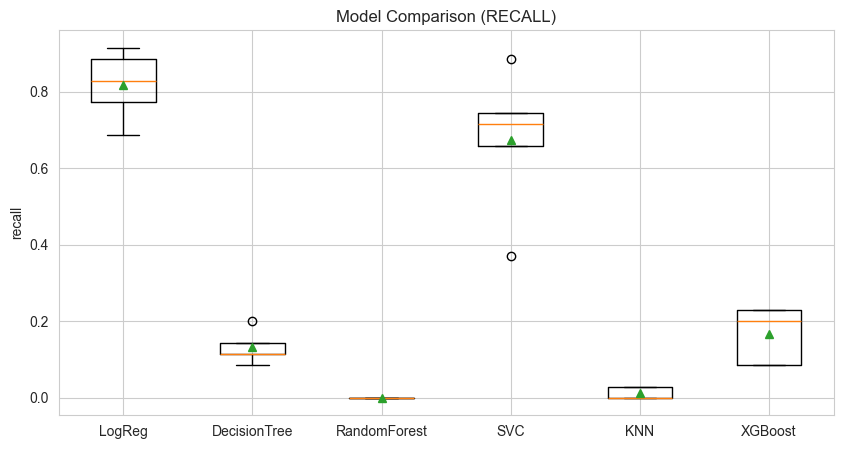

In [ ]:
# 4. Model Benchmarking Strategy

# Danh sách Models
models = [
    ('LogReg', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    ('DecisionTree', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ('RandomForest', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ('SVC', SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE)),
    ('KNN', KNeighborsClassifier()),
    ('XGBoost', XGBClassifier(scale_pos_weight=19, eval_metric='logloss', random_state=RANDOM_STATE)) 
]

def benchmark_models(models, X, y, cv=5, scoring='recall'):
    results = []
    names = []
    print(f">> Benchmarking models using {scoring.upper()} score...")
    
    kfold = StratifiedKFold(n_splits=cv, shuffle=True, random_state=RANDOM_STATE)
    
    for name, model in models:
        cv_results = cross_val_score(model, X, y, cv=kfold, scoring=scoring)
        results.append(cv_results)
        names.append(name)
        print(f"{name}: {cv_results.mean():.4f} (+/- {cv_results.std():.4f})")
        
    # Visualization
    plt.figure(figsize=(10, 5))
    plt.boxplot(results, labels=names, showmeans=True)
    plt.title(f'Model Comparison ({scoring.upper()})')
    plt.ylabel(scoring)
    plt.show()

# Chạy Benchmark trên tập TRAIN
benchmark_models(models, X_train_processed, y_train, scoring='recall')

In [ ]:
# 5. Train Best Model
# Dựa trên kết quả benchmark, LogReg thường ổn định nhất về Recall cho Stroke
print(">> Training Final Model: Logistic Regression...")

best_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
best_model.fit(X_train_processed, y_train)

# Dự đoán xác suất trên tập Test
y_pred_proba = best_model.predict_proba(X_test_processed)[:, 1] # trả về xác suất lớp dương 0%, 70%...
y_pred_default = best_model.predict(X_test_processed)

print("Training complete.")

>> Training Final Model: Logistic Regression...
Training complete.


--- Evaluation on TEST Set (Threshold = 0.5) ---
              precision    recall  f1-score   support

           0       0.98      0.75      0.85       730
           1       0.13      0.76      0.23        37

    accuracy                           0.75       767
   macro avg       0.56      0.75      0.54       767
weighted avg       0.94      0.75      0.82       767

ROC-AUC Score: 0.8221


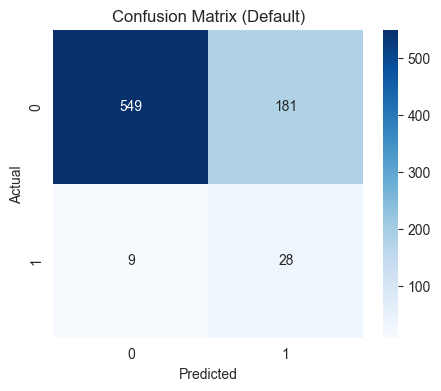

In [6]:
# 6. Evaluation with Default Threshold (0.5)
print("--- Evaluation on TEST Set (Threshold = 0.5) ---")
print(classification_report(y_test, y_pred_default))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_default), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Default)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

>> Best Threshold found: 0.7536
   Best F1-Score: 0.3586
   Recall at Best Threshold: 0.7027
   Precision at Best Threshold: 0.2407


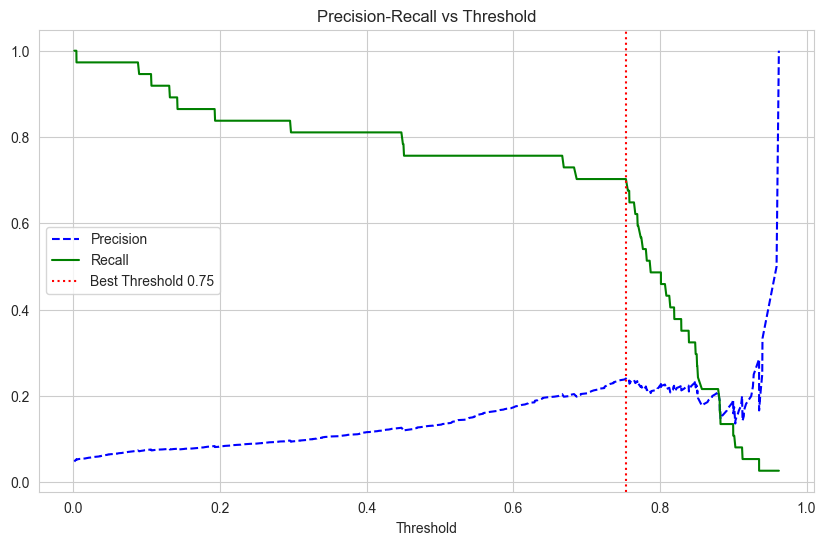


--- Optimized Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.89      0.93       730
           1       0.24      0.70      0.36        37

    accuracy                           0.88       767
   macro avg       0.61      0.80      0.65       767
weighted avg       0.95      0.88      0.91       767



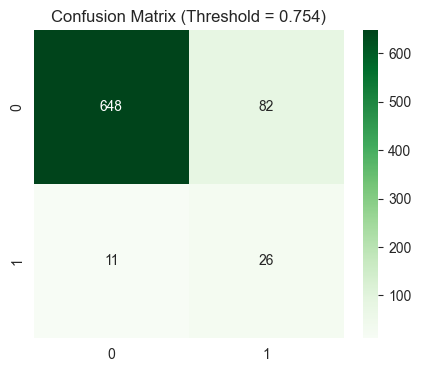

In [ ]:
# 7. Optimize Threshold using Precision-Recall Curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Tính F1-score cho mọi ngưỡng
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f">> Best Threshold found: {best_threshold:.4f}")
print(f"   Best F1-Score: {f1_scores[best_idx]:.4f}")
print(f"   Recall at Best Threshold: {recalls[best_idx]:.4f}")
print(f"   Precision at Best Threshold: {precisions[best_idx]:.4f}")

# Visualize Curve
def plot_pr_curve(precisions, recalls, threshold_sc):
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision")
    plt.plot(thresholds, recalls[:-1], "g-", label="Recall")
    plt.axvline(x=threshold_sc, color='r', linestyle=':', label=f'Best Threshold {threshold_sc:.2f}')
    plt.xlabel("Threshold")
    plt.legend(loc="best")
    plt.title("Precision-Recall vs Threshold")
    plt.show()

plot_pr_curve(precisions, recalls, best_threshold)

# Đánh giá lại với ngưỡng mới
y_pred_optimized = (y_pred_proba >= best_threshold).astype(int) # 50 28 79 /// 75 => không, không, có

print("\n--- Optimized Classification Report ---")
print(classification_report(y_test, y_pred_optimized))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_optimized), annot=True, fmt='d', cmap='Greens')
plt.title(f'Confusion Matrix (Threshold = {best_threshold:.3f})')
plt.show()